
##Project Title

Seasonal Agriculture Performance Analysis

The project should stay focused on the seasonal-performance problem rather than becoming a generic analysis of every column. This matches the supplied project brief, which asks you to investigate seasonal differences, patterns, relationships and variations.

##Problem Statement

Use this as the central problem:

Agricultural performance varies across seasons because of changes in environmental conditions, farming practices, resource availability and economic factors. The objective of this project is to analyze agricultural data across different seasons and identify meaningful patterns, trends, relationships and differences in agricultu





In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("/content/seasonal_agriculture_performance_dataset.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 4000
Columns: 28


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,7.14,32.8,75.8,61.3,91.0,Drip,242.7,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,5.20,32.0,82.1,35.4,121.8,Flood,271.4,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,5.82,8.1,118.5,51.5,117.9,Drip,162.6,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,5.98,23.7,138.6,55.6,115.5,Rainfed,182.2,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,6.90,29.3,124.1,69.0,121.4,Flood,244.9,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   object 
 1   State                          4000 non-null   object 
 2   District                       4000 non-null   object 
 3   Crop                           4000 non-null   object 
 4   Season                         4000 non-null   object 
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   f

In [5]:
df.describe()

,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
count,4000.000000,3952.000000,4000.00000,4000.000000,4000.000000,4000.000000,3960.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,3968.000000,4000.000000,4000.000000,4.000000e+03,4.000000e+03,4.000000e+03,4000.000000,4000.000000,4000.000000
mean,7.888265,601.152657,26.81890,63.210500,7.323050,6.701010,26.508232,120.250825,57.781850,104.760050,186.036000,5.070935,0.826138,5.270595,43.246210,44714.166250,5.263036e+05,6.378600e+05,1.115565e+05,6045.570250,5.385214,46.365875
std,4.223764,288.925025,3.81818,11.960834,1.121186,0.641461,6.712484,31.216452,17.015074,27.742681,60.260583,1.978879,0.101747,13.361398,126.880521,30266.161922,2.944191e+05,6.369747e+05,5.450819e+05,5572.944306,8.838101,12.424417
min,0.500000,80.000000,16.20000,25.000000,3.500000,5.200000,8.000000,40.000000,15.000000,30.000000,40.000000,0.500000,0.650000,0.300000,0.150000,2594.000000,2.682600e+04,6.107000e+03,-1.019223e+06,128.000000,0.135000,5.000000
25%,4.260000,370.200000,23.90000,54.775000,6.600000,6.260000,21.700000,98.500000,46.200000,86.200000,143.975000,3.690000,0.740000,1.050000,5.020000,21429.250000,2.745775e+05,2.075172e+05,-1.487318e+05,2268.750000,1.661000,37.300000
50%,7.895000,582.000000,26.90000,63.000000,7.300000,6.690000,26.400000,120.100000,57.500000,105.100000,186.250000,5.120000,0.830000,1.740000,11.770000,25913.000000,5.190825e+05,4.568305e+05,3.673000e+03,4435.000000,2.937500,46.400000
75%,11.650000,834.950000,29.60000,71.900000,8.100000,7.140000,31.300000,141.225000,69.400000,123.600000,227.200000,6.400000,0.910000,2.840000,24.355000,68279.000000,7.619965e+05,8.368748e+05,2.161878e+05,7829.750000,5.150250,54.900000
max,15.000000,1395.200000,39.70000,95.000000,11.000000,8.400000,47.000000,220.000000,120.000000,200.000000,400.000000,12.080000,1.000000,101.440000,1424.400000,131240.000000,1.349990e+06,5.080900e+06,4.345421e+06,40902.000000,79.800000,88.900000


In [6]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 Farm_ID
Farm_ID
SF13984    1
SF13983    1
SF13982    1
SF13981    1
SF13980    1
          ..
SF10005    1
SF10004    1
SF10003    1
SF10002    1
SF10001    1
Name: count, Length: 4000, dtype: int64

 State
State
Andhra Pradesh    529
Telangana         516
Maharashtra       512
Madhya Pradesh    497
Karnataka         489
Gujarat           488
Tamil Nadu        485
Punjab            484
Name: count, dtype: int64

 District
District
Ludhiana    427
Warangal    422
Nalgonda    415
Erode       403
Rajkot      401
Krishna     393
Indore      392
Guntur      390
Raichur     386
Nashik      371
Name: count, dtype: int64

 Crop
Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305
Name: count, dtype: int64

 Season
Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64

 Irrigation_Method
Irrigation_Method
Flood        1310
Rainfed      1041
Drip          915
Sprinkler     734
Name: 

In [7]:
for col in df.columns:
    print(col, ":", df[col].nunique())

Farm_ID : 4000
State : 8
District : 10
Crop : 8
Season : 3
Farm_Area_Hectares : 1370
Rainfall_mm : 3256
Avg_Temperature_C : 204
Humidity_pct : 573
Sunlight_Hours_Day : 71
Soil_pH : 313
Soil_Moisture_pct : 343
Nitrogen_kg_ha : 1229
Phosphorus_kg_ha : 760
Potassium_kg_ha : 1137
Irrigation_Method : 4
Fertilizer_kg_ha : 1881
Pesticide_Litre_ha : 851
Seed_Quality_Score : 36
Yield_Tonnes_Ha : 738
Production_Tonnes : 2528
Market_Price_INR_Tonne : 3760
Total_Cost_INR : 3995
Revenue_INR : 3993
Profit_INR : 3992
Water_Used_m3 : 3407
Water_Efficiency_t_per_1000m3 : 3127
Disease_Pest_Risk_pct : 597


In [8]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Rainfall_mm          48
Soil_Moisture_pct    40
Yield_Tonnes_Ha      32
dtype: int64


In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Rainfall_mm          48
Soil_Moisture_pct    40
Yield_Tonnes_Ha      32
dtype: int64


In [10]:
numeric_missing = [
    "Rainfall_mm",
    "Soil_Moisture_pct",
    "Yield_Tonnes_Ha"
]

for col in numeric_missing:
    df[col] = df[col].fillna(df[col].median())

In [11]:
print(df.isnull().sum().sum())

0


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
print(df.shape)

(4000, 28)


In [15]:
df["Profit_Margin_pct"] = (
    df["Profit_INR"] / df["Revenue_INR"] * 100
)
df["Cost_per_Tonne"] = (
    df["Total_Cost_INR"] / df["Production_Tonnes"]
)

In [16]:
df["Revenue_per_Hectare"] = (
    df["Revenue_INR"] / df["Farm_Area_Hectares"]
)

In [17]:
df["Profit_per_Hectare"] = (
    df["Profit_INR"] / df["Farm_Area_Hectares"]
)

In [18]:
df["Season"].value_counts()

,count
Season,
Kharif,1779
Rabi,1627
Zaid,594


Season
Kharif    1779
Rabi      1627
Zaid       594
dtype: int64


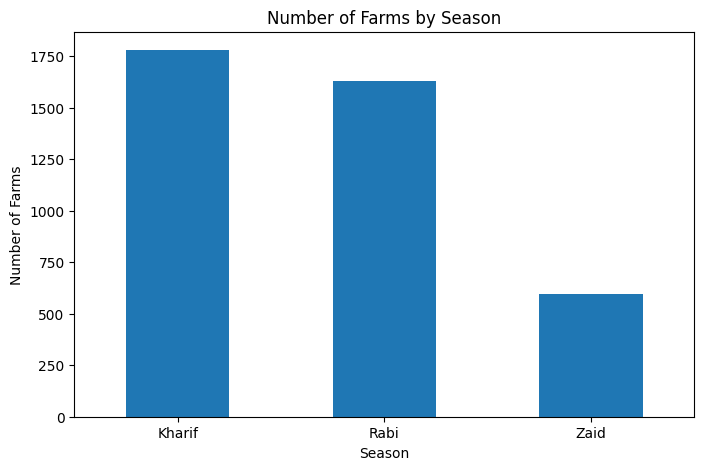

In [22]:
##Analyze seasonal distribution

seasonal_distribution = df.groupby("Season").size()

print(seasonal_distribution)
plt.figure(figsize=(8,5))

df["Season"].value_counts().plot(kind="bar")

plt.title("Number of Farms by Season")
plt.xlabel("Season")
plt.ylabel("Number of Farms")
plt.xticks(rotation=0)

plt.show()


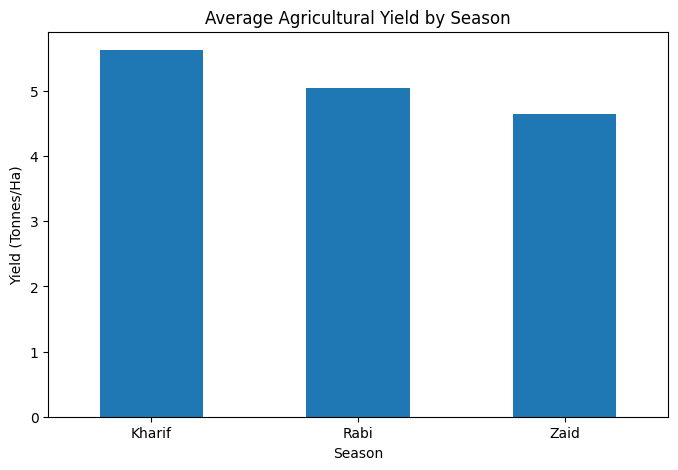

In [25]:
#Main analysis: Season vs Yield
season_yield = (
    df.groupby("Season")["Yield_Tonnes_Ha"]
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(8,5))

season_yield.plot(kind="bar")

plt.title("Average Agricultural Yield by Season")
plt.xlabel("Season")
plt.ylabel("Yield (Tonnes/Ha)")
plt.xticks(rotation=0)

plt.show()

**Interpretation**

Kharif shows the highest average yield in the supplied dataset, followed by Rabi and Zaid. This indicates that agricultural performance differs across seasons and supports further investigation of environmental and resource-related factors.





Season
Kharif    178914.647555
Rabi       87689.470191
Zaid      -24804.824916
Name: Profit_INR, dtype: float64


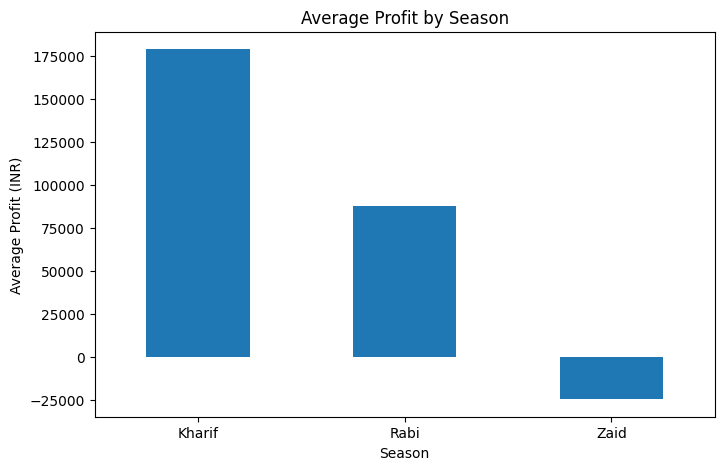

In [28]:
##Season vs Profit
season_profit = (
    df.groupby("Season")["Profit_INR"]
    .mean()
    .sort_values(ascending=False)
)

print(season_profit)

plt.figure(figsize=(8,5))

season_profit.plot(kind="bar")

plt.title("Average Profit by Season")
plt.xlabel("Season")
plt.ylabel("Average Profit (INR)")
plt.xticks(rotation=0)

plt.show()

Season
Kharif    46.311192
Rabi      41.486712
Zaid      38.886111
Name: Production_Tonnes, dtype: float64


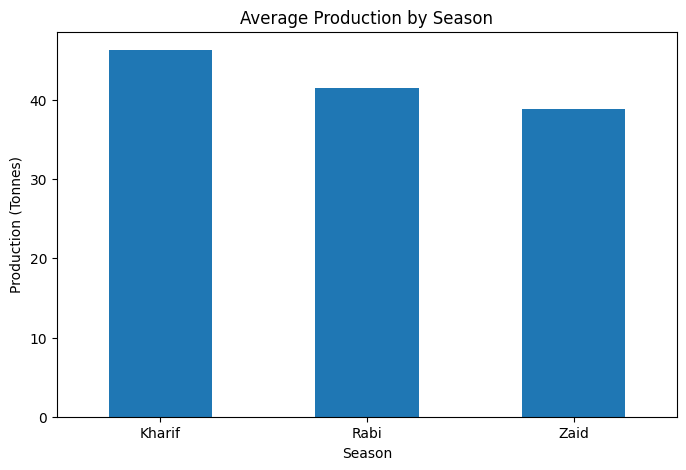

In [29]:
##Season vs Production
season_production = (
    df.groupby("Season")["Production_Tonnes"]
    .mean()
)

print(season_production)
plt.figure(figsize=(8,5))

season_production.plot(kind="bar")

plt.title("Average Production by Season")
plt.ylabel("Production (Tonnes)")
plt.xlabel("Season")
plt.xticks(rotation=0)

plt.show()

Crop
Sugarcane    46.642361
Maize         2.710036
Rice          2.431304
Wheat         2.108013
Chilli        1.542767
Groundnut     1.322901
Cotton        1.229783
Pulses        0.921512
Name: Yield_Tonnes_Ha, dtype: float64


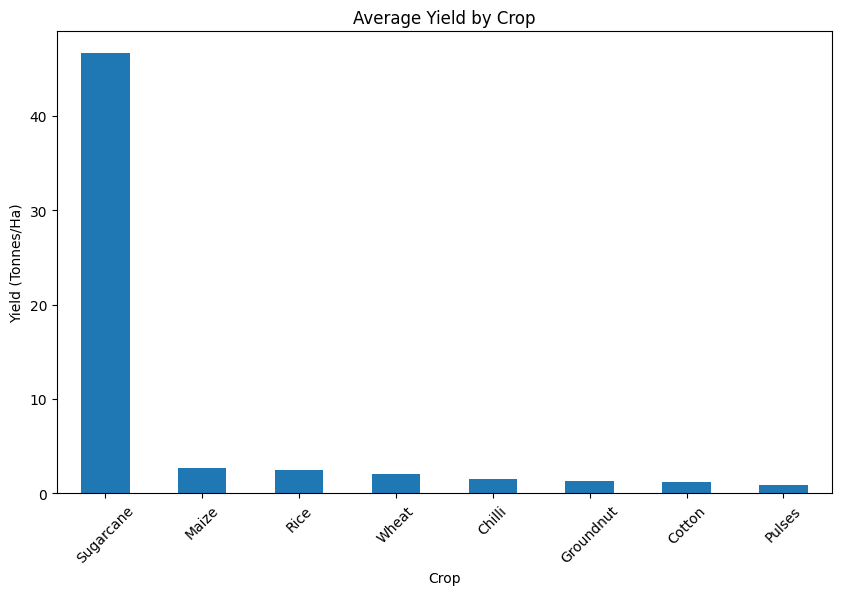

In [30]:
##Crop-wise analysis
crop_yield = (
    df.groupby("Crop")["Yield_Tonnes_Ha"]
    .mean()
    .sort_values(ascending=False)
)

print(crop_yield)
plt.figure(figsize=(10,6))

crop_yield.plot(kind="bar")

plt.title("Average Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Yield (Tonnes/Ha)")
plt.xticks(rotation=45)

plt.show()

Season     Kharif   Rabi   Zaid
Crop                           
Chilli       1.73   1.47   1.20
Cotton       1.37   1.20   0.96
Groundnut    1.48   1.23   1.04
Maize        2.97   2.60   2.29
Pulses       1.04   0.88   0.67
Rice         2.70   2.32   1.90
Sugarcane   53.46  43.29  38.42
Wheat        2.25   2.06   1.75


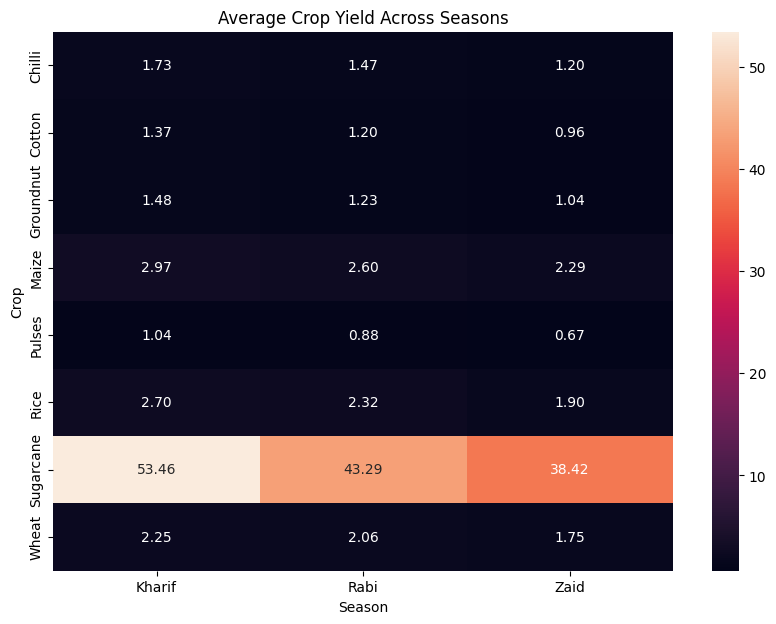

In [31]:
##Crop + Season analysis
crop_season = pd.pivot_table(
    df,
    values="Yield_Tonnes_Ha",
    index="Crop",
    columns="Season",
    aggfunc="mean"
)

print(crop_season.round(2))
plt.figure(figsize=(10,7))

sns.heatmap(
    crop_season,
    annot=True,
    fmt=".2f"
)

plt.title("Average Crop Yield Across Seasons")
plt.xlabel("Season")
plt.ylabel("Crop")

plt.show()

In [32]:
##Irrigation analysis
irrigation = df.groupby("Irrigation_Method")[
    [
        "Yield_Tonnes_Ha",
        "Water_Efficiency_t_per_1000m3",
        "Profit_INR"
    ]
].mean()

print(irrigation.round(2))

                   Yield_Tonnes_Ha  Water_Efficiency_t_per_1000m3  Profit_INR
Irrigation_Method                                                            
Drip                          6.58                           6.27   219626.00
Flood                         4.86                           3.44    73354.02
Rainfed                       4.60                           7.56    79050.37
Sprinkler                     5.16                           4.67    91121.08


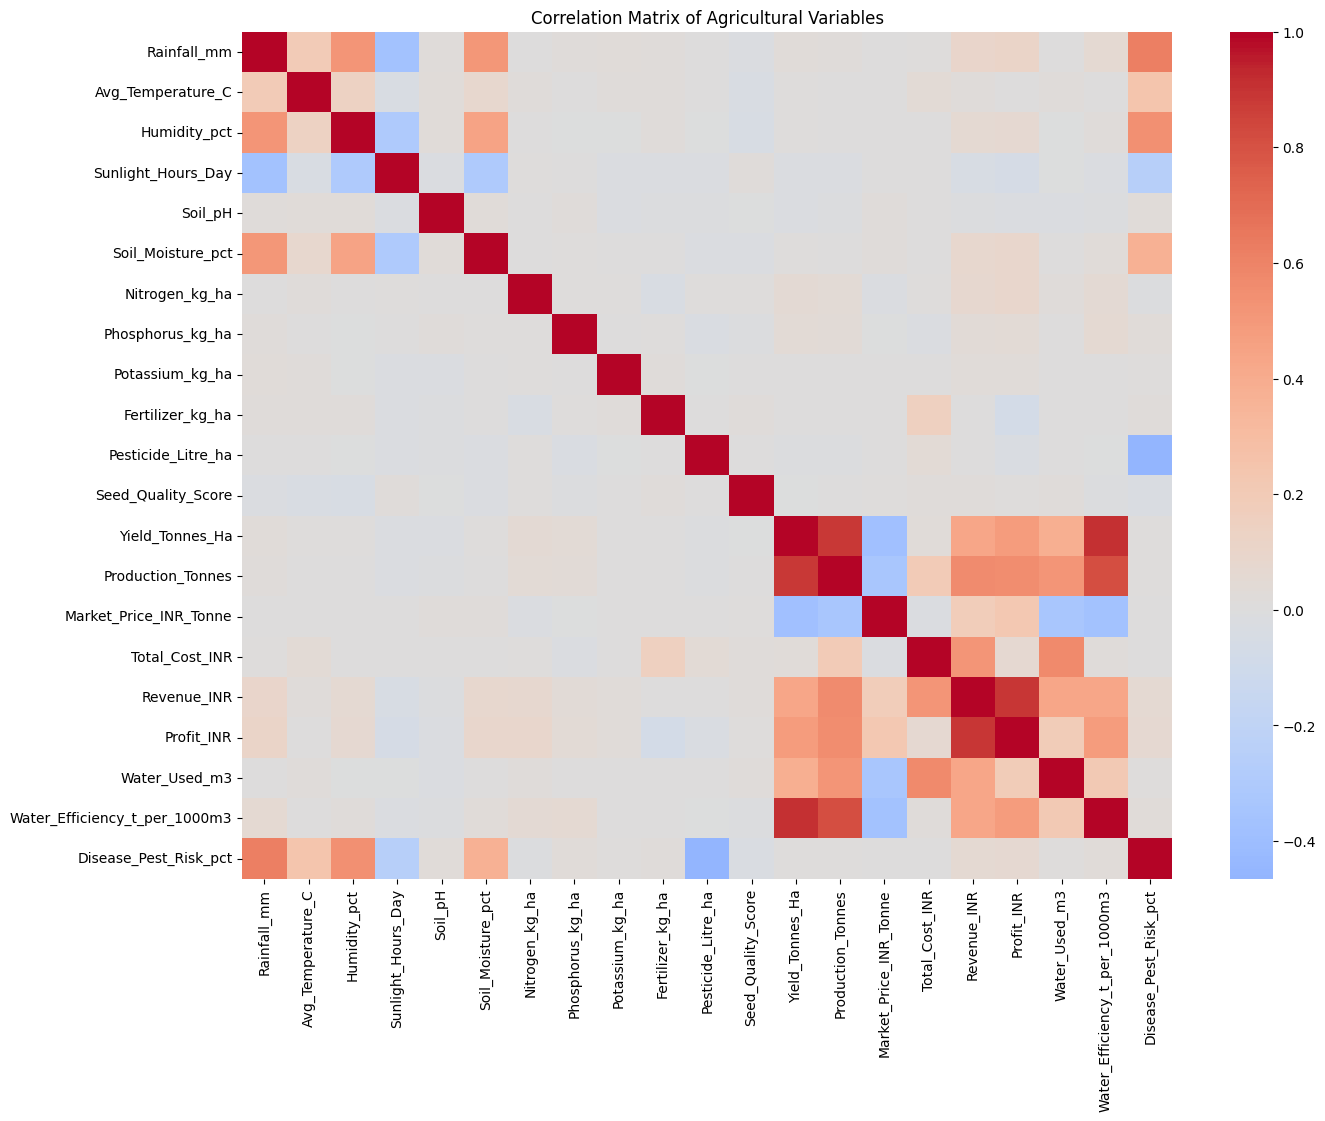

In [35]:
##corelation analysis
numeric_cols = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct",
    "Nitrogen_kg_ha",
    "Phosphorus_kg_ha",
    "Potassium_kg_ha",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Seed_Quality_Score",
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Market_Price_INR_Tonne",
    "Total_Cost_INR",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3",
    "Disease_Pest_Risk_pct"
]

corr = df[numeric_cols].corr()
plt.figure(figsize=(15,11))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Agricultural Variables")
plt.show()

In [36]:
#Specifically investigate yield relationships
yield_corr = (
    corr["Yield_Tonnes_Ha"]
    .sort_values(ascending=False)
)

print(yield_corr)


Yield_Tonnes_Ha                  1.000000
Water_Efficiency_t_per_1000m3    0.912568
Production_Tonnes                0.882813
Profit_INR                       0.488466
Revenue_INR                      0.432152
Water_Used_m3                    0.386294
Nitrogen_kg_ha                   0.053149
Phosphorus_kg_ha                 0.047941
Rainfall_mm                      0.030951
Total_Cost_INR                   0.030622
Disease_Pest_Risk_pct            0.014292
Humidity_pct                     0.012297
Soil_Moisture_pct                0.010999
Avg_Temperature_C                0.009996
Potassium_kg_ha                  0.003382
Fertilizer_kg_ha                 0.000018
Seed_Quality_Score              -0.007209
Pesticide_Litre_ha              -0.007779
Sunlight_Hours_Day              -0.015341
Soil_pH                         -0.020672
Market_Price_INR_Tonne          -0.382607
Name: Yield_Tonnes_Ha, dtype: float64


In [38]:
#statistical comparison
from scipy.stats import f_oneway

groups = [
    group["Yield_Tonnes_Ha"].values
    for _, group in df.groupby("Season")
]

stat, p_value = f_oneway(*groups)

print("F-statistic:", stat)
print("p-value:", p_value)
if p_value < 0.05:
    print("There is statistically significant evidence of differences in mean yield across seasons.")
else:
    print("There is insufficient statistical evidence of differences in mean yield across seasons.")

F-statistic: 1.5438804542488311
p-value: 0.21367813841792296
There is insufficient statistical evidence of differences in mean yield across seasons.


In [39]:
kpi = {
    "Total Farms": len(df),
    "Number of States": df["State"].nunique(),
    "Number of Crops": df["Crop"].nunique(),
    "Number of Seasons": df["Season"].nunique(),
    "Average Yield": df["Yield_Tonnes_Ha"].mean(),
    "Average Profit": df["Profit_INR"].mean(),
    "Average Water Efficiency":
        df["Water_Efficiency_t_per_1000m3"].mean()
}

kpi

{'Total Farms': 4000,
 'Number of States': 8,
 'Number of Crops': 8,
 'Number of Seasons': 3,
 'Average Yield': np.float64(5.242349999999999),
 'Average Profit': np.float64(111556.465),
 'Average Water Efficiency': np.float64(5.385214249999999)}

In [40]:
season_kpi = df.groupby("Season")[
    [
        "Yield_Tonnes_Ha",
        "Production_Tonnes",
        "Profit_INR",
        "Water_Efficiency_t_per_1000m3",
        "Disease_Pest_Risk_pct"
    ]
].mean()

season_kpi.round(2)

,Yield_Tonnes_Ha,Production_Tonnes,Profit_INR,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
Season,,,,,
Kharif,5.63,46.31,178914.65,5.89,54.47
Rabi,5.04,41.49,87689.47,5.19,40.48
Zaid,4.64,38.89,-24804.82,4.41,38.22


In [41]:
#Profitability Risk Analysis
df["Profit_Status"] = np.where(
    df["Profit_INR"] >= 0,
    "Profitable",
    "Loss"
)

profit_status = pd.crosstab(
    df["Season"],
    df["Profit_Status"],
    normalize="index"
) * 100

profit_status.round(2)


Profit_Status,Loss,Profitable
Season,,
Kharif,42.21,57.79
Rabi,51.14,48.86
Zaid,64.48,35.52


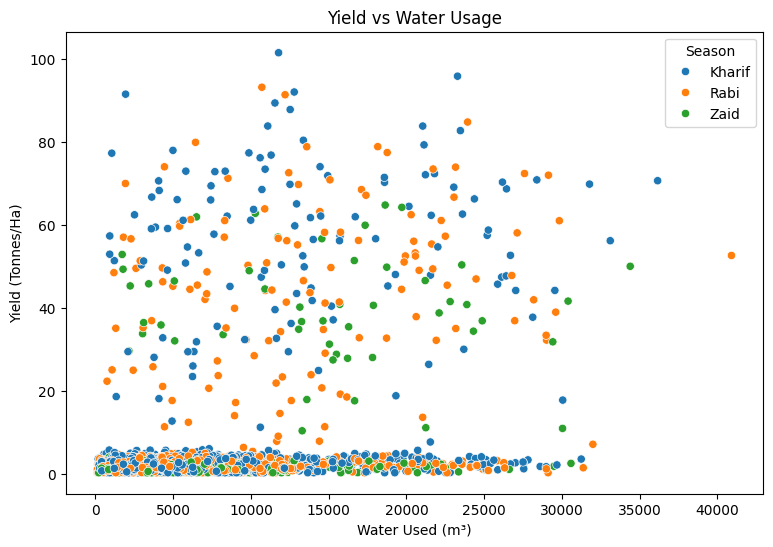

In [43]:
#Yield vs Water Efficiency
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Water_Used_m3",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Yield vs Water Usage")
plt.xlabel("Water Used (m³)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

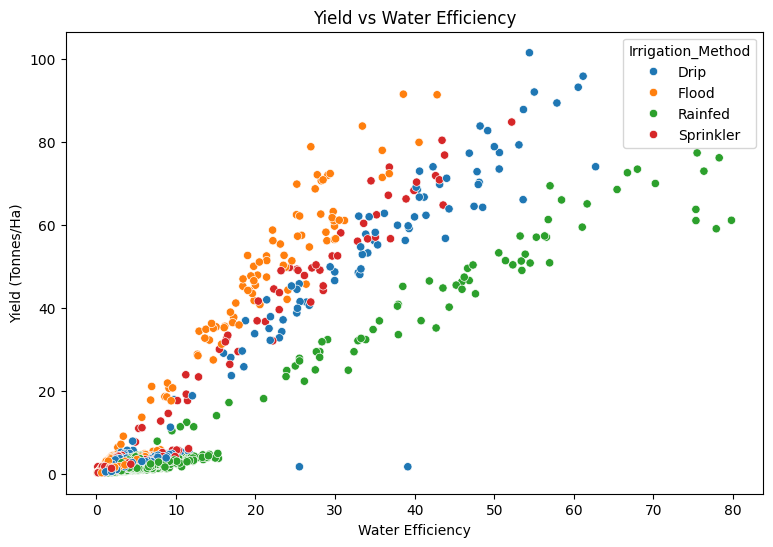

In [45]:
#Yield vs Water Efficiency
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Water_Efficiency_t_per_1000m3",
    y="Yield_Tonnes_Ha",
    hue="Irrigation_Method"
)

plt.title("Yield vs Water Efficiency")
plt.xlabel("Water Efficiency")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()


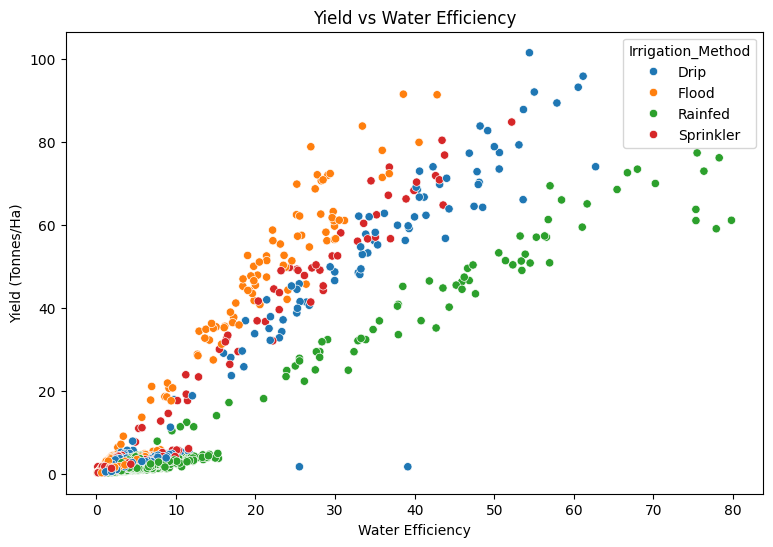

In [46]:
#Yield vs Water Efficiency
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Water_Efficiency_t_per_1000m3",
    y="Yield_Tonnes_Ha",
    hue="Irrigation_Method"
)

plt.title("Yield vs Water Efficiency")
plt.xlabel("Water Efficiency")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

In [48]:

#Environmental Driver Analysis
environmental_cols = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_pH",
    "Soil_Moisture_pct"
]

environmental_corr = df[
    environmental_cols + ["Yield_Tonnes_Ha"]
].corr()["Yield_Tonnes_Ha"].sort_values(
    ascending=False
)

environmental_corr

,Yield_Tonnes_Ha
Yield_Tonnes_Ha,1.000000
Rainfall_mm,0.030951
Humidity_pct,0.012297
Soil_Moisture_pct,0.010999
Avg_Temperature_C,0.009996
Sunlight_Hours_Day,-0.015341
Soil_pH,-0.020672


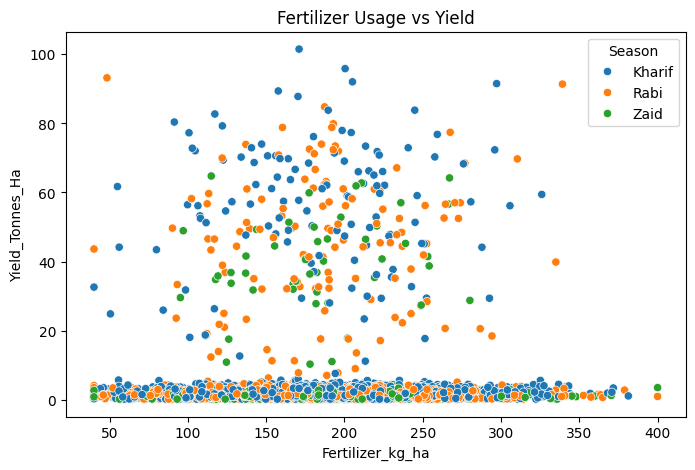

In [49]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Fertilizer_kg_ha",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Fertilizer Usage vs Yield")
plt.show()

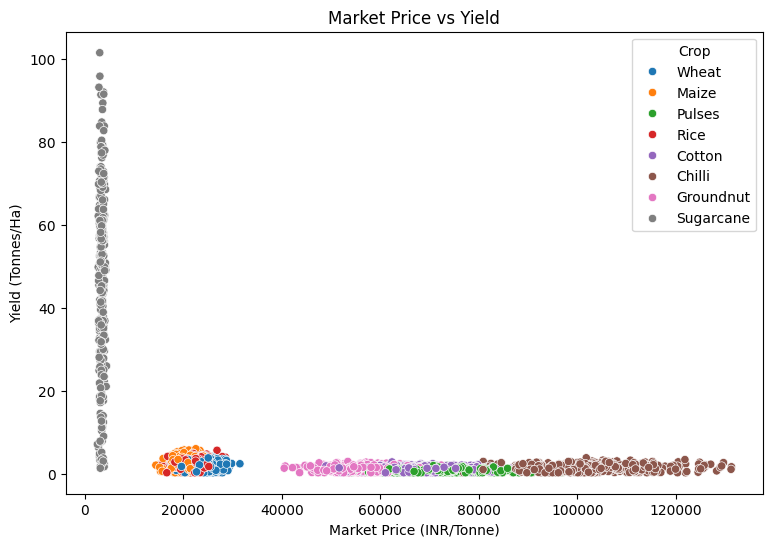

In [50]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="Market_Price_INR_Tonne",
    y="Yield_Tonnes_Ha",
    hue="Crop"
)

plt.title("Market Price vs Yield")
plt.xlabel("Market Price (INR/Tonne)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

In [51]:
season_summary = df.groupby("Season").agg(
    Yield=("Yield_Tonnes_Ha", "mean"),
    Profit=("Profit_INR", "mean"),
    Water_Efficiency=(
        "Water_Efficiency_t_per_1000m3", "mean"
    ),
    Risk=("Disease_Pest_Risk_pct", "mean")
)

season_summary
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

score_cols = [
    "Yield",
    "Profit",
    "Water_Efficiency"
]

season_summary[score_cols] = scaler.fit_transform(
    season_summary[score_cols]
)

# Risk is undesirable, so invert it
season_summary["Risk_Score"] = 1 - scaler.fit_transform(
    df.groupby("Season")[["Disease_Pest_Risk_pct"]].mean()
)

season_summary["Overall_Score"] = (
    season_summary["Yield"] * 0.30 +
    season_summary["Profit"] * 0.30 +
    season_summary["Water_Efficiency"] * 0.20 +
    season_summary["Risk_Score"] * 0.20
)

season_summary.sort_values(
    "Overall_Score",
    ascending=False
)

,Yield,Profit,Water_Efficiency,Risk,Risk_Score,Overall_Score
Season,,,,,,
Kharif,1.000000,1.000000,1.000000,54.467903,0.000000,0.800000
Rabi,0.403243,0.552202,0.522715,40.482114,0.860598,0.563296
Zaid,0.000000,0.000000,0.000000,38.216667,1.000000,0.200000
